In [13]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [14]:
df=pd.read_csv("student_dataV2.csv")

In [16]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [17]:
df.tail()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1.0,6.0,9773.0,1,1,125.0,1,1,1.0,...,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1.0,2.0,9773.0,1,1,120.0,105,1,1.0,...,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1.0,1.0,9500.0,1,1,154.0,1,37,37.0,...,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1.0,1.0,9147.0,1,1,180.0,1,37,37.0,...,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10.0,1.0,9773.0,1,1,152.0,22,38,37.0,...,0,6.0,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [21]:
df.describe()

,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,Admission grade,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,...,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000
mean,18.681044,1.728263,8858.817026,0.890579,4.575709,132.625380,19.577980,22.285131,10.982293,126.986969,...,0.137571,0.542792,6.235187,8.067650,4.436549,10.229241,0.150738,11.569580,1.229830,0.003426
std,17.468337,1.314328,2059.439226,0.312202,10.209099,13.197875,15.599978,15.339215,26.472462,14.481624,...,0.691625,1.921199,2.195195,3.949725,3.015759,5.212774,0.755229,2.665064,1.382054,2.267922
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.800000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,53.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   str    
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   str    
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4423

In [32]:
df.isnull().sum()

Marital status                                    0
Application mode                                  1
Application order                                 1
Course                                            3
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    4
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            1
Mother's occupation                               1
Father's occupation                               1
Admission grade                                   2
Displaced                                         0
Educational special needs                         0
Debtor                                            1
Tuition fees up to date                           1
Gender                                            0
Scholarship holder                                0
Age at enrol

In [28]:
X = df.drop(columns=['Target'])
X = X.replace(['?', 'Unknown', 'Five', 'Na'], np.nan)

In [29]:
print("Missing values per colum before transformation:")
print(X.isnull().sum)

Missing values per colum before transformation:
<bound method DataFrame.sum of       Marital status  Application mode  Application order  Course  \
0              False             False              False   False   
1              False             False              False   False   
2              False             False              False   False   
3              False             False              False   False   
4              False             False              False   False   
...              ...               ...                ...     ...   
4419           False             False              False   False   
4420           False             False              False   False   
4421           False             False              False   False   
4422           False             False              False   False   
4423           False             False              False   False   

      Daytime/evening attendance  Previous qualification  \
0                          False

In [33]:
df['Target'].value_counts()

Target
Graduate    2207
Dropout     1419
Enrolled     794
Grad           1
graduate       1
Drop           1
dropout        1
Name: count, dtype: int64

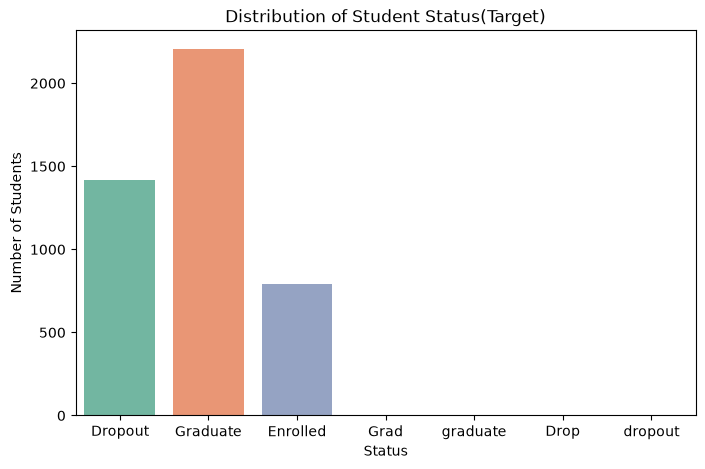

In [34]:
#
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Target', hue='Target', palette='Set2', legend=False)
plt.title('Distribution of Student Status(Target)')
plt.xlabel('Status')
plt.ylabel('Number of Students')
plt.show()

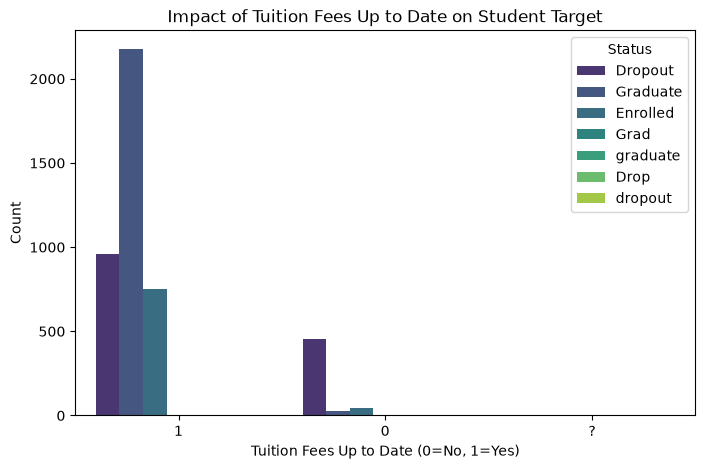

In [46]:
#Check if student paid tuition on time 

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Tuition fees up to date', hue='Target', palette='viridis')
plt.title('Impact of Tuition Fees Up to Date on Student Target')
plt.xlabel('Tuition Fees Up to Date (0=No, 1=Yes)')
plt.ylabel('Count')
plt.legend(title='Status')
plt.show()

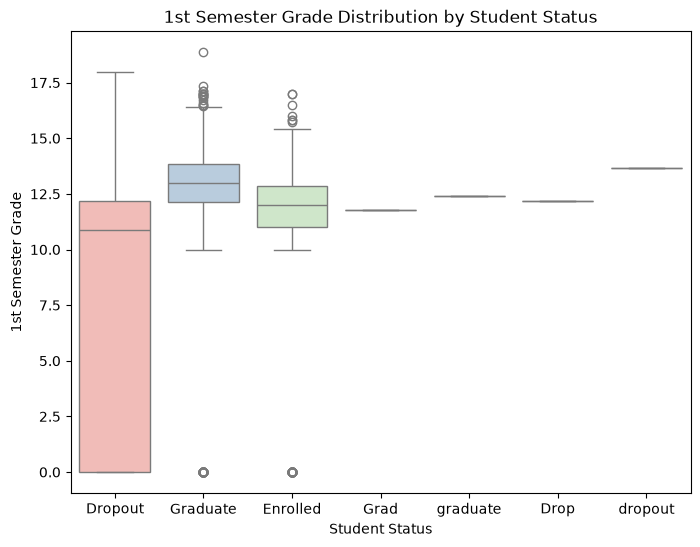

In [36]:
#Curricular units 1st semester
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Target', y='Curricular units 1st sem (grade)', hue='Target', palette='Pastel1', legend=False)
plt.title('1st Semester Grade Distribution by Student Status')
plt.xlabel('Student Status')
plt.ylabel('1st Semester Grade')
plt.show()